# 06 · 모델 최적화 — 특성공학 · 교차검증 · 하이퍼파라미터 튜닝
### 실습으로 배우는 신약개발 AI — 강의 목차 ⑧ 모델 최적화

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/DrugAI/blob/main/06_Model_Optimization.ipynb)

| 항목 | 내용 |
|---|---|
| **학습 목표** | ① 특성공학(분자 표현형 비교·특성 선택) ② 교차검증과 **스캐폴드 분할** ③ 하이퍼파라미터 튜닝 (Grid · Random · **베이지안 최적화 Optuna**) ④ 학습곡선·검증곡선 ⑤ **SHAP** 으로 모델 해석 ⑥ 모델 저장·문서화 |
| **데이터** | BACE-1(알츠하이머 표적) 저해제 1,513개의 pIC50 — ChEMBL 기반 MoleculeNet |
| **실행 환경** | CPU · 약 15~20분 (튜닝 셀이 가장 오래 걸림) |

> **pIC50 = −log10(IC50 [M])** : 클수록 강력한 저해제 (pIC50 7 = 100 nM, pIC50 5 = 10 µM)

In [1]:
%pip install -q rdkit koreanize-matplotlib xgboost optuna shap
import koreanize_matplotlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
import warnings; warnings.filterwarnings("ignore")
from rdkit import Chem, RDLogger; RDLogger.DisableLog("rdApp.*")
from rdkit.Chem import Descriptors, MACCSkeys, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import (KFold, GroupKFold, cross_val_score, GridSearchCV,
                                     RandomizedSearchCV, learning_curve, validation_curve)
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from xgboost import XGBRegressor
print("✅ 준비 완료")

Note: you may need to restart the kernel to use updated packages.


✅ 준비 완료


분자 수: 1513   pIC50 범위 2.5 ~ 10.5


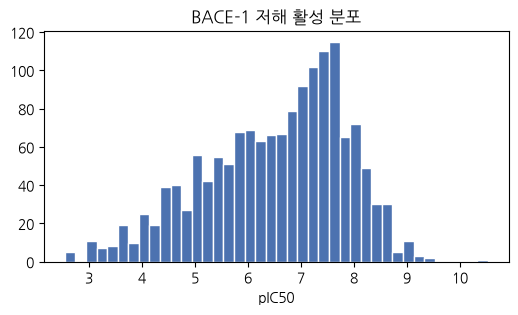

In [2]:
bace = pd.read_csv("https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/bace.csv")
bace["mol_obj"] = bace["mol"].apply(Chem.MolFromSmiles)
bace = bace[bace["mol_obj"].notna()].reset_index(drop=True)
y = bace["pIC50"].values
print("분자 수:", len(bace), f"  pIC50 범위 {y.min():.1f} ~ {y.max():.1f}")
plt.figure(figsize=(6, 3)); plt.hist(y, bins=40, color="#4C72B0", edgecolor="white")
plt.xlabel("pIC50"); plt.title("BACE-1 저해 활성 분포"); plt.show()

## 1. 특성공학 ① — 어떤 분자 표현형이 활성 예측에 좋은가?
| 표현형 | 설명 |
|---|---|
| Morgan r2 (1024/2048) | 반경 2 (ECFP4) 부분구조 유무 |
| Morgan r3 | 반경 3 (ECFP6) — 더 큰 부분구조 |
| Morgan **count** | 유무(0/1) 대신 **등장 횟수** |
| MACCS | 전문가가 정의한 166개 구조 키 |
| RDKit 기술자 | 물리화학 기술자 ~200개 |
| 기술자 + Morgan count | 결합 |

In [3]:
mols = bace["mol_obj"].tolist()
def morgan(r, n, count=False):
    g = rdFingerprintGenerator.GetMorganGenerator(radius=r, fpSize=n)
    f = g.GetCountFingerprintAsNumPy if count else g.GetFingerprintAsNumPy
    return np.array([f(m) for m in mols], dtype=np.float32)

desc = pd.DataFrame([Descriptors.CalcMolDescriptors(m) for m in mols]).replace([np.inf, -np.inf], np.nan)
desc = desc.loc[:, desc.notna().all() & (desc.std() > 0)].clip(-1e6, 1e6)

FEATS = {"Morgan r2 1024": morgan(2, 1024), "Morgan r2 2048": morgan(2, 2048), "Morgan r3 2048": morgan(3, 2048),
         "Morgan r2 count": morgan(2, 2048, count=True),
         "MACCS": np.array([np.array(MACCSkeys.GenMACCSKeys(m)) for m in mols], dtype=np.float32),
         "RDKit 기술자": desc.values.astype(np.float32)}
FEATS["기술자 + Morgan count"] = np.hstack([FEATS["RDKit 기술자"], FEATS["Morgan r2 count"]])

kf = KFold(5, shuffle=True, random_state=42)
rf = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42, max_features=0.3)
fe = {}
for k, X in FEATS.items():
    t = time.time(); sc = cross_val_score(rf, X, y, cv=kf, scoring="r2")
    fe[k] = sc.mean(); print(f"{k:22s} 특성 {X.shape[1]:5d}개  CV R²={sc.mean():.3f} ± {sc.std():.3f}  ({time.time()-t:.0f}s)")

Morgan r2 1024         특성  1024개  CV R²=0.714 ± 0.032  (3s)


Morgan r2 2048         특성  2048개  CV R²=0.715 ± 0.033  (5s)


Morgan r3 2048         특성  2048개  CV R²=0.700 ± 0.037  (6s)


Morgan r2 count        특성  2048개  CV R²=0.723 ± 0.035  (5s)


MACCS                  특성   167개  CV R²=0.657 ± 0.031  (1s)


RDKit 기술자              특성   193개  CV R²=0.697 ± 0.041  (3s)


기술자 + Morgan count     특성  2241개  CV R²=0.716 ± 0.040  (7s)


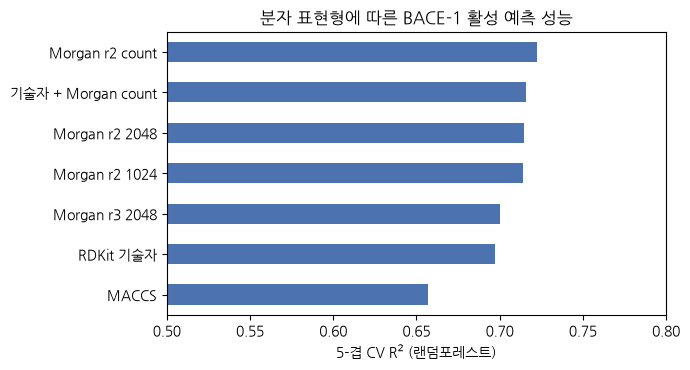

In [4]:
pd.Series(fe).sort_values().plot.barh(figsize=(7, 3.8), color="#4C72B0")
plt.xlim(0.5, 0.8); plt.xlabel("5-겹 CV R$^2$ (랜덤포레스트)"); plt.title("분자 표현형에 따른 BACE-1 활성 예측 성능"); plt.tight_layout(); plt.show()

## 2. 특성공학 ② — 특성 선택 (Feature Selection)
특성이 많을수록 좋은 것은 아닙니다. **중요도 상위 k개만** 써도 성능이 유지되면 모델이 단순·빠르고 해석이 쉬워집니다.

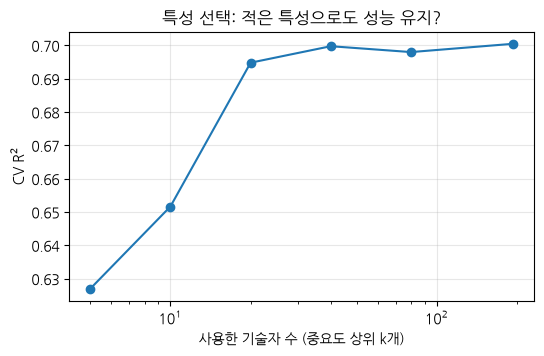

상위 10개 기술자: ['Chi0', 'MinEStateIndex', 'fr_NH2', 'fr_ester', 'SMR_VSA10', 'PEOE_VSA7', 'Chi2v', 'HeavyAtomMolWt', 'SMR_VSA4', 'MaxEStateIndex']


In [5]:
X_desc = desc
rf_full = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=42).fit(X_desc, y)
order = pd.Series(rf_full.feature_importances_, index=X_desc.columns).sort_values(ascending=False)
ks, scores = [5, 10, 20, 40, 80, X_desc.shape[1]], []
for k in ks:
    scores.append(cross_val_score(rf, X_desc[order.index[:k]], y, cv=kf, scoring="r2").mean())
plt.figure(figsize=(6, 3.5)); plt.plot(ks, scores, "o-"); plt.xscale("log")
plt.xlabel("사용한 기술자 수 (중요도 상위 k개)"); plt.ylabel("CV R$^2$"); plt.title("특성 선택: 적은 특성으로도 성능 유지?"); plt.grid(alpha=0.3); plt.show()
print("상위 10개 기술자:", list(order.index[:10]))

> ⚠️ 위 방법은 **전체 데이터로 중요도를 구한 뒤** 같은 데이터로 CV 를 하므로 약간 낙관적입니다(누수).
> 엄격하게는 특성 선택도 **교차검증 안에서(Pipeline)** 수행해야 합니다.

## 3. ⭐ 데이터 분할 전략 — 무작위 분할 vs 스캐폴드(scaffold) 분할
신약개발에서 모델이 실제로 하는 일은 **처음 보는 골격(scaffold)의 새 분자**를 예측하는 것입니다.
- **무작위 분할**: 거의 같은 유도체가 학습·평가에 나뉘어 들어가 성능이 **부풀려짐**
- **스캐폴드 분할**: Bemis-Murcko 골격이 같은 분자는 같은 쪽에 → **현실적인 성능**

In [6]:
scaf = [MurckoScaffold.MurckoScaffoldSmiles(mol=m) for m in mols]
groups = pd.factorize(pd.Series(scaf))[0]
print("고유 스캐폴드 수:", groups.max() + 1, "/ 분자 수:", len(mols))

X = FEATS["기술자 + Morgan count"]
r_random = cross_val_score(rf, X, y, cv=KFold(5, shuffle=True, random_state=42), scoring="r2")
r_scaf = cross_val_score(rf, X, y, cv=GroupKFold(5), groups=groups, scoring="r2")
print(f"무작위 5-겹 CV R²  = {r_random.mean():.3f} ± {r_random.std():.3f}")
print(f"스캐폴드 5-겹 CV R² = {r_scaf.mean():.3f} ± {r_scaf.std():.3f}   ← 새로운 골격에 대한 현실적 성능")

고유 스캐폴드 수: 671 / 분자 수: 1513


무작위 5-겹 CV R²  = 0.716 ± 0.040
스캐폴드 5-겹 CV R² = 0.668 ± 0.028   ← 새로운 골격에 대한 현실적 성능


## 4. ⭐ 하이퍼파라미터 튜닝 — Grid vs Random vs 베이지안(Optuna)
- **파라미터**: 모델이 데이터로 학습하는 값 (트리 분할 기준, 신경망 가중치)
- **하이퍼파라미터**: 사람이 정하는 설정 (트리 깊이, 학습률, 트리 개수 …)

| 방법 | 원리 | 장단점 |
|---|---|---|
| Grid Search | 모든 조합을 다 시험 | 확실하지만 조합 폭발 |
| Random Search | 무작위 조합 n개 시험 | 같은 예산으로 더 넓게 탐색 |
| **베이지안 최적화 (Optuna TPE)** | 지금까지 결과로 '유망한 영역'을 추정해 다음 조합 선택 | 적은 시도로 좋은 조합 — 실무 표준 |

XGBoost 를 대상으로, 같은 3-겹 CV 기준으로 비교합니다.

In [7]:
X = FEATS["기술자 + Morgan count"]
cv3 = KFold(3, shuffle=True, random_state=0)
base = XGBRegressor(n_estimators=200, tree_method="hist", random_state=42, n_jobs=-1, verbosity=0)
tune = {}

t = time.time()
print("기본 설정 CV R²:", round(cross_val_score(base, X, y, cv=cv3, scoring="r2").mean(), 3))

grid = {"max_depth": [4, 6, 8], "learning_rate": [0.05, 0.1], "colsample_bytree": [0.3, 0.7]}
gs = GridSearchCV(base, grid, cv=cv3, scoring="r2", n_jobs=1).fit(X, y)
tune["Grid (12조합)"] = (gs.best_score_, time.time() - t, gs.best_params_)

t = time.time()
dist = {"max_depth": [3, 4, 5, 6, 7, 8, 10], "learning_rate": [0.02, 0.03, 0.05, 0.08, 0.1, 0.15],
        "colsample_bytree": [0.2, 0.3, 0.5, 0.7, 0.9], "subsample": [0.6, 0.8, 1.0], "min_child_weight": [1, 3, 5]}
rs = RandomizedSearchCV(base, dist, n_iter=10, cv=cv3, scoring="r2", random_state=0, n_jobs=1).fit(X, y)
tune["Random (10회)"] = (rs.best_score_, time.time() - t, rs.best_params_)
for k, v in tune.items(): print(f"{k:14s} 최고 CV R²={v[0]:.3f}  ({v[1]:.0f}초)  {v[2]}")

기본 설정 CV R²: 0.675


Grid (12조합)    최고 CV R²=0.712  (37초)  {'colsample_bytree': 0.3, 'learning_rate': 0.05, 'max_depth': 6}
Random (10회)   최고 CV R²=0.717  (32초)  {'subsample': 0.6, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.9}


Optuna 최고 CV R²=0.721  (53초)
최적 하이퍼파라미터: {'max_depth': 5, 'learning_rate': 0.051, 'colsample_bytree': 0.348, 'subsample': 0.991, 'min_child_weight': 8, 'reg_lambda': 0.01}


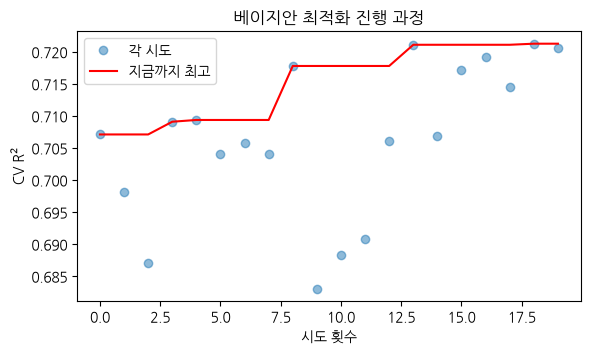

In [8]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {"max_depth": trial.suggest_int("max_depth", 3, 10),
              "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
              "colsample_bytree": trial.suggest_float("colsample_bytree", 0.1, 1.0),
              "subsample": trial.suggest_float("subsample", 0.5, 1.0),
              "min_child_weight": trial.suggest_int("min_child_weight", 1, 8),
              "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True)}
    m = XGBRegressor(n_estimators=200, tree_method="hist", random_state=42, n_jobs=-1, verbosity=0, **params)
    return cross_val_score(m, X, y, cv=cv3, scoring="r2").mean()

t = time.time()
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
study.optimize(objective, n_trials=20)
tune["Optuna (20회)"] = (study.best_value, time.time() - t, study.best_params)
print(f"Optuna 최고 CV R²={study.best_value:.3f}  ({time.time()-t:.0f}초)")
print("최적 하이퍼파라미터:", {k: round(v, 3) if isinstance(v, float) else v for k, v in study.best_params.items()})

vals = [t_.value for t_ in study.trials]
plt.figure(figsize=(6.5, 3.5))
plt.plot(vals, "o", alpha=0.5, label="각 시도"); plt.plot(np.maximum.accumulate(vals), "r-", label="지금까지 최고")
plt.xlabel("시도 횟수"); plt.ylabel("CV R$^2$"); plt.title("베이지안 최적화 진행 과정"); plt.legend(); plt.show()

## 5. 학습곡선 & 검증곡선 — 데이터를 더 모을까? 모델을 더 복잡하게 할까?

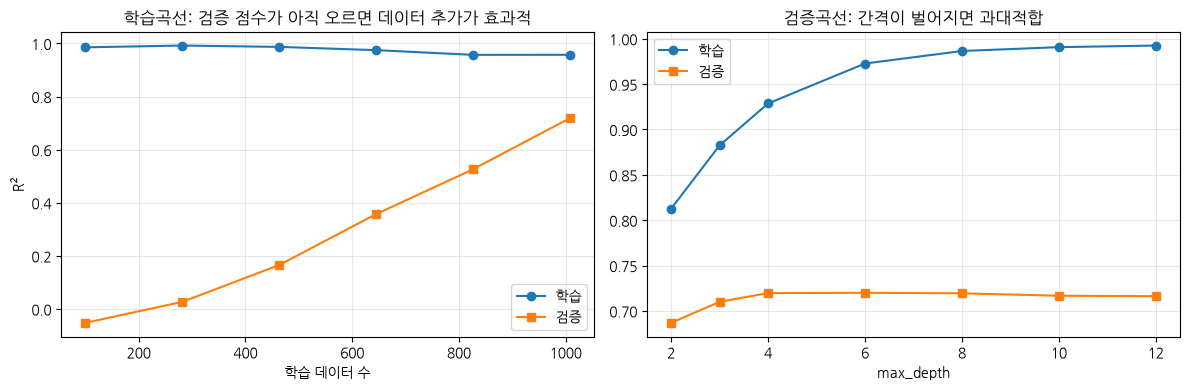

In [9]:
best_params = study.best_params
best = XGBRegressor(n_estimators=300, tree_method="hist", random_state=42, n_jobs=-1, verbosity=0, **best_params)
sizes, tr_s, va_s = learning_curve(best, X, y, cv=cv3, scoring="r2", train_sizes=np.linspace(0.1, 1.0, 6))
depths = [2, 3, 4, 6, 8, 10, 12]
p = {k: v for k, v in best_params.items() if k != "max_depth"}
vc_tr, vc_va = validation_curve(XGBRegressor(n_estimators=300, tree_method="hist", random_state=42, n_jobs=-1, verbosity=0, **p),
                                X, y, param_name="max_depth", param_range=depths, cv=cv3, scoring="r2")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(sizes, tr_s.mean(1), "o-", label="학습"); ax[0].plot(sizes, va_s.mean(1), "s-", label="검증")
ax[0].set_xlabel("학습 데이터 수"); ax[0].set_ylabel("R$^2$"); ax[0].set_title("학습곡선: 검증 점수가 아직 오르면 데이터 추가가 효과적"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(depths, vc_tr.mean(1), "o-", label="학습"); ax[1].plot(depths, vc_va.mean(1), "s-", label="검증")
ax[1].set_xlabel("max_depth"); ax[1].set_title("검증곡선: 간격이 벌어지면 과대적합"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. 최종 평가 — 스캐폴드 기준 홀드아웃 테스트
튜닝에 한 번도 쓰지 않은 **새 골격 분자 20%** 로 최종 성능을 확인합니다.

기본 XGBoost    R²=0.630  MAE=0.629
튜닝된 XGBoost   R²=0.684  MAE=0.582


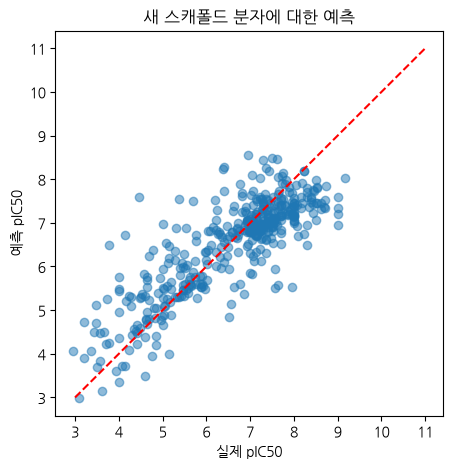

In [10]:
from sklearn.model_selection import GroupShuffleSplit
tr_idx, te_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=1).split(X, y, groups))
default = XGBRegressor(n_estimators=300, tree_method="hist", random_state=42, n_jobs=-1, verbosity=0).fit(X[tr_idx], y[tr_idx])
tuned = XGBRegressor(n_estimators=300, tree_method="hist", random_state=42, n_jobs=-1, verbosity=0, **best_params).fit(X[tr_idx], y[tr_idx])
for name, m in [("기본 XGBoost", default), ("튜닝된 XGBoost", tuned)]:
    p_ = m.predict(X[te_idx]); print(f"{name:12s}  R²={r2_score(y[te_idx], p_):.3f}  MAE={mean_absolute_error(y[te_idx], p_):.3f}")
pred = tuned.predict(X[te_idx])
plt.figure(figsize=(5, 5)); plt.scatter(y[te_idx], pred, alpha=0.5)
plt.plot([3, 11], [3, 11], "r--"); plt.xlabel("실제 pIC50"); plt.ylabel("예측 pIC50"); plt.title("새 스캐폴드 분자에 대한 예측"); plt.show()

## 7. ⭐ SHAP — "왜 이 분자를 강력하다고 예측했나?"
**SHAP**(SHapley Additive exPlanations)은 게임이론의 섀플리 값으로 **각 특성이 예측을 얼마나 올리고 내렸는지** 계산합니다.
해석이 쉽도록 **RDKit 기술자만** 사용한 모델로 설명합니다.
- 점 하나 = 분자 하나, 색 = 특성 값(빨강=높음), 가로 위치 = 예측에 대한 기여(+ 는 pIC50 상승)

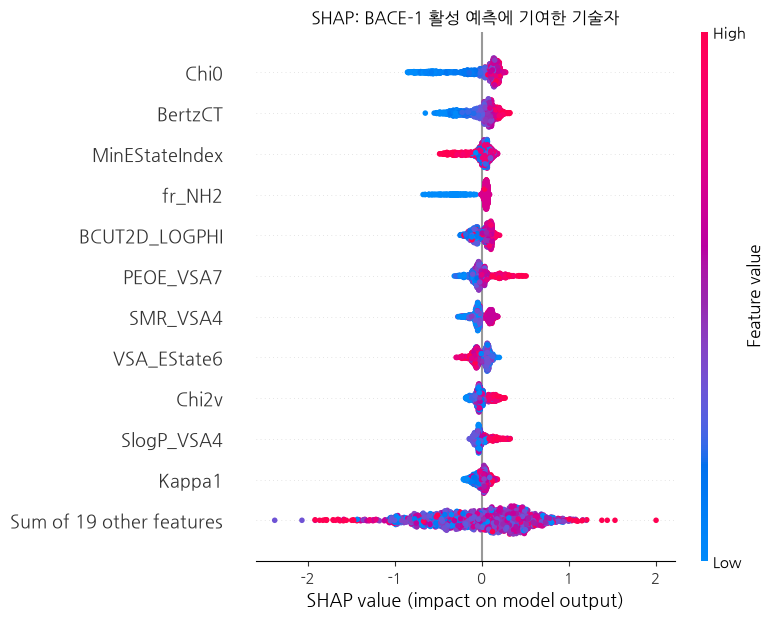

In [11]:
import shap
Xd = X_desc[order.index[:30]]
m_desc = XGBRegressor(n_estimators=300, tree_method="hist", random_state=42, verbosity=0, **best_params).fit(Xd, y)
explainer = shap.TreeExplainer(m_desc)
sv = explainer(Xd)
shap.plots.beeswarm(sv, max_display=12, show=False); plt.title("SHAP: BACE-1 활성 예측에 기여한 기술자"); plt.tight_layout(); plt.show()

예측 pIC50: 10.26  실제: 10.522879


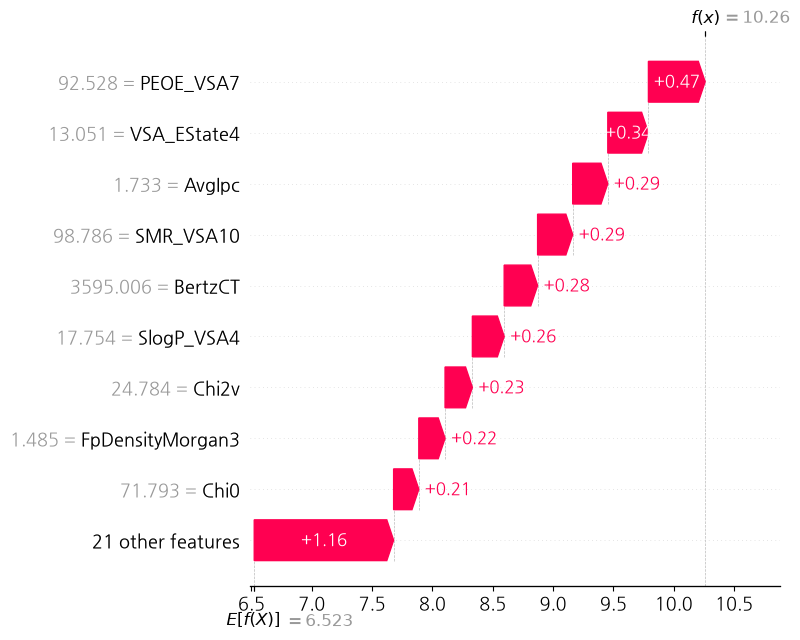

In [12]:
# 개별 분자 설명 — 가장 강력하다고 예측된 분자의 근거
i = int(np.argmax(m_desc.predict(Xd)))
print("예측 pIC50:", round(float(m_desc.predict(Xd.iloc[[i]])[0]), 2), " 실제:", y[i])
shap.plots.waterfall(sv[i], max_display=10, show=False); plt.tight_layout(); plt.show()

## 8. 모델 저장과 문서화 (재현성)
최종 모델과 함께 **어떤 데이터·특성·하이퍼파라미터·검증 방식**으로 만들었는지 기록합니다 (GMP-AI 의 Model Card 와 같은 개념).

In [13]:
import joblib, json, datetime, platform, xgboost, sklearn
joblib.dump(tuned, "bace_xgb_tuned.joblib")
card = {"model": "XGBRegressor", "target": "BACE-1 pIC50", "data": "MoleculeNet BACE (n=%d)" % len(y),
        "features": "RDKit descriptors (%d) + Morgan r2 count 2048" % desc.shape[1],
        "hyperparameters": best_params, "validation": "scaffold GroupShuffleSplit 80/20, tuning by 3-fold CV (Optuna 20 trials)",
        "test_R2": round(float(r2_score(y[te_idx], pred)), 3), "created": datetime.date.today().isoformat(),
        "versions": {"python": platform.python_version(), "xgboost": xgboost.__version__, "sklearn": sklearn.__version__}}
json.dump(card, open("bace_model_card.json", "w"), indent=2, ensure_ascii=False)
print(json.dumps(card, indent=2, ensure_ascii=False))

{
  "model": "XGBRegressor",
  "target": "BACE-1 pIC50",
  "data": "MoleculeNet BACE (n=1513)",
  "features": "RDKit descriptors (193) + Morgan r2 count 2048",
  "hyperparameters": {
    "max_depth": 5,
    "learning_rate": 0.050673026286526354,
    "colsample_bytree": 0.3481930378795508,
    "subsample": 0.991242321355204,
    "min_child_weight": 8,
    "reg_lambda": 0.009705494996802788
  },
  "validation": "scaffold GroupShuffleSplit 80/20, tuning by 3-fold CV (Optuna 20 trials)",
  "test_R2": 0.684,
  "created": "2026-10-12",
  "versions": {
    "python": "3.12.13",
    "xgboost": "3.4.1",
    "sklearn": "1.9.1"
  }
}


## 🧪 LLM 코딩 과제
```
FEATS['Morgan r2 count'] 특성으로 RandomForestRegressor 의 n_estimators, max_depth, max_features, min_samples_leaf 를
Optuna 로 20회 튜닝하는 코드를 써줘. 교차검증은 스캐폴드 기반 GroupKFold(groups=groups, 3겹)로 해줘.
```

In [14]:
# ✏️ LLM 코드 붙여넣기

## ✅ 정리 — 모델 최적화 체크리스트
1. **표현형부터 비교**: 하이퍼파라미터보다 특성 선택의 효과가 큰 경우가 많다
2. **분할 전략이 성능을 결정**: 신약은 **스캐폴드 분할**, 시계열·공정은 시간/배치 분할
3. **튜닝은 CV 안에서**, 최종 평가는 한 번도 안 쓴 테스트 세트로
4. 베이지안 최적화(Optuna)로 적은 시도에 좋은 조합
5. 학습곡선 → 데이터 추가 여부, 검증곡선 → 복잡도 결정
6. **SHAP** 으로 근거 제시, **모델 카드**로 재현성 확보

➡️ **다음 예제 07**: 모델로 고른 후보를 표적 단백질에 **분자 도킹**하는 가상 스크리닝 파이프라인